# ENZERA - 02 Experiments: imbalance handling and XGBoost settings

**Question.** Can we beat the current XGBoost (class weights, `ml/train.py`) with SMOTE oversampling or other
hyperparameters?

**Protocol (identical to `ml/train.py`).** Same 70/15/15 split and seed. Models are fitted on `tr_fit` (85% of train).
The decision threshold is tuned for best F1 on the validation split, never on test. Metrics come from the
same `evaluate()` function used in training.

**Decision rule (fixed before running).** We replace the current model only if a setting improves **test PR-AUC by
at least 0.01 AND test "theft caught in top 10%" by at least 0.01**, and is not worse on validation PR-AUC.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from ml.features import compute_features, split_wide
from ml.train import SEED, best_f1_threshold, evaluate   # same metric code as training
import matplotlib.pyplot as plt
%matplotlib inline

ids, labels, dates, values = split_wide(pd.read_csv(ROOT / "data/raw/data.csv"))
X = compute_features(values, dates).to_numpy(); y = labels

idx = np.arange(len(ids))
tr, rest = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
te, demo = train_test_split(rest, test_size=0.50, stratify=labels[rest], random_state=SEED)
tr_fit, val = train_test_split(tr, test_size=0.15, stratify=labels[tr], random_state=SEED)
print("tr_fit / val / test =", len(tr_fit), len(val), len(te), "| thieves in test:", int(y[te].sum()))

tr_fit / val / test = 25211 4449 6356 | thieves in test: 543


## Settings compared

In [2]:
neg, pos = np.bincount(y[tr_fit]); spw = round(neg / pos, 3)
BASE = {"n_estimators": 400, "max_depth": 5, "learning_rate": 0.05, "subsample": 0.8, "colsample_bytree": 0.8}

settings = {
    # name: (xgboost params, use SMOTE?)
    "current: class weights":        ({**BASE, "scale_pos_weight": spw}, False),
    "SMOTE (no class weights)":      ({**BASE, "scale_pos_weight": 1.0}, True),
    "HP-A shallow, 800 trees":       ({**BASE, "max_depth": 3, "n_estimators": 800, "scale_pos_weight": spw}, False),
    "HP-B deep + regularised":       ({**BASE, "max_depth": 7, "min_child_weight": 5, "reg_lambda": 5.0,
                                       "scale_pos_weight": spw}, False),
    "HP-C slow, 1500 trees":         ({**BASE, "max_depth": 6, "n_estimators": 1500, "learning_rate": 0.02,
                                       "colsample_bytree": 0.6, "scale_pos_weight": spw}, False),
}
print("scale_pos_weight =", spw)
pd.DataFrame({k: v[0] | {"SMOTE": v[1]} for k, v in settings.items()}).T

scale_pos_weight = 10.721


,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,scale_pos_weight,SMOTE,min_child_weight,reg_lambda
current: class weights,400,5,0.05,0.8,0.8,10.721,False,NaN,NaN
SMOTE (no class weights),400,5,0.05,0.8,0.8,1.0,True,NaN,NaN
"HP-A shallow, 800 trees",800,3,0.05,0.8,0.8,10.721,False,NaN,NaN
HP-B deep + regularised,400,7,0.05,0.8,0.8,10.721,False,5,5.0
"HP-C slow, 1500 trees",1500,6,0.02,0.8,0.6,10.721,False,NaN,NaN


**SMOTE** creates synthetic thieves by interpolating between a real thief and one of its 5 nearest thief
neighbours in feature space, until both classes are equal in size. It is applied **only to `tr_fit`**: validation and test
keep the real class balance, otherwise the metrics would be meaningless.

In [3]:
rows, test_prob = [], {}
for name, (params, use_smote) in settings.items():
    Xf, yf = X[tr_fit], y[tr_fit]
    if use_smote:
        Xf, yf = SMOTE(random_state=SEED).fit_resample(Xf, yf)
    model = XGBClassifier(**params, eval_metric="aucpr", n_jobs=-1, random_state=SEED).fit(Xf, yf)
    p_val = model.predict_proba(X[val])[:, 1]
    p_te = model.predict_proba(X[te])[:, 1]
    r = evaluate(y[te], p_te, best_f1_threshold(y[val], p_val))
    r["val_pr_auc"] = float(average_precision_score(y[val], p_val))
    r["train_rows"] = len(yf)
    rows.append({"setting": name, **r}); test_prob[name] = p_te

res = pd.DataFrame(rows).set_index("setting")
cols = ["precision", "recall", "f1", "roc_auc", "pr_auc", "recall_at_top10", "precision_at_top10",
        "threshold", "val_pr_auc", "train_rows"]
res[cols].round(3)

,precision,recall,f1,roc_auc,pr_auc,recall_at_top10,precision_at_top10,threshold,val_pr_auc,train_rows
setting,,,,,,,,,,
current: class weights,0.363,0.366,0.365,0.788,0.332,0.405,0.346,0.673,0.338,25211
SMOTE (no class weights),0.326,0.343,0.334,0.757,0.296,0.366,0.313,0.630,0.271,46120
"HP-A shallow, 800 trees",0.297,0.466,0.363,0.786,0.322,0.394,0.337,0.637,0.338,25211
HP-B deep + regularised,0.377,0.337,0.356,0.780,0.328,0.394,0.337,0.616,0.331,25211
"HP-C slow, 1500 trees",0.372,0.378,0.375,0.783,0.332,0.405,0.346,0.574,0.336,25211


### Sanity check: the 'current' row must reproduce `reports/metrics.json`

In [4]:
saved = json.loads((ROOT / "reports/metrics.json").read_text())["results"]["xgboost"]
cur = res.loc["current: class weights"]
for k in ["precision", "recall", "f1", "roc_auc", "pr_auc", "recall_at_top10"]:
    print(f"{k:16s} notebook {cur[k]:.4f}   metrics.json {saved[k]:.4f}")
assert all(abs(cur[k] - saved[k]) < 1e-6 for k in ["pr_auc", "roc_auc", "recall_at_top10"])
print("Reproduced exactly.")

precision        notebook 0.3631   metrics.json 0.3631
recall           notebook 0.3665   metrics.json 0.3665
f1               notebook 0.3648   metrics.json 0.3648
roc_auc          notebook 0.7884   metrics.json 0.7884
pr_auc           notebook 0.3325   metrics.json 0.3325
recall_at_top10  notebook 0.4052   metrics.json 0.4052
Reproduced exactly.


## Results table (test split, 6,356 customers)

In [5]:
table = res.rename(columns={"precision": "Precision", "recall": "Recall", "f1": "F1", "roc_auc": "ROC-AUC",
                            "pr_auc": "PR-AUC", "recall_at_top10": "Theft caught in top 10%",
                            "val_pr_auc": "PR-AUC (validation)"})
table = table[["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "Theft caught in top 10%", "PR-AUC (validation)"]].round(3)
table.to_csv(ROOT / "reports/experiments.csv")
table

,Precision,Recall,F1,ROC-AUC,PR-AUC,Theft caught in top 10%,PR-AUC (validation)
setting,,,,,,,
current: class weights,0.363,0.366,0.365,0.788,0.332,0.405,0.338
SMOTE (no class weights),0.326,0.343,0.334,0.757,0.296,0.366,0.271
"HP-A shallow, 800 trees",0.297,0.466,0.363,0.786,0.322,0.394,0.338
HP-B deep + regularised,0.377,0.337,0.356,0.780,0.328,0.394,0.331
"HP-C slow, 1500 trees",0.372,0.378,0.375,0.783,0.332,0.405,0.336


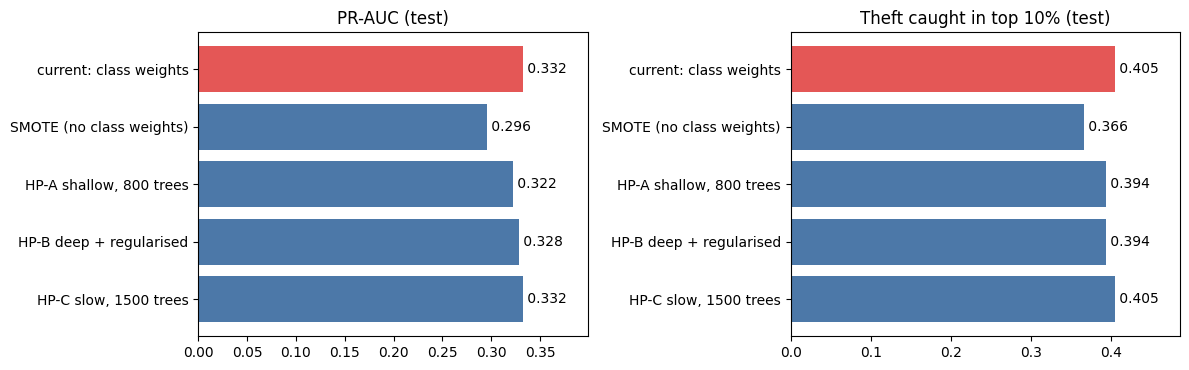

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col in zip(axes, ["PR-AUC", "Theft caught in top 10%"]):
    v = table[col]
    ax.barh(v.index[::-1], v.values[::-1], color=["#E45756" if i == "current: class weights" else "#4C78A8" for i in v.index[::-1]])
    for i, val in enumerate(v.values[::-1]):
        ax.text(val, i, f" {val:.3f}", va="center")
    ax.set_xlim(0, v.max() * 1.2); ax.set_title(col + " (test)")
fig.tight_layout(); fig.savefig(ROOT / "reports/experiments.png", dpi=120); plt.show()

## Apply the decision rule

In [7]:
base = res.loc["current: class weights"]
dec = pd.DataFrame({
    "d PR-AUC (test)": res["pr_auc"] - base["pr_auc"],
    "d top10 recall (test)": res["recall_at_top10"] - base["recall_at_top10"],
    "d PR-AUC (val)": res["val_pr_auc"] - base["val_pr_auc"],
}).drop("current: class weights")
dec["clearly better?"] = (dec["d PR-AUC (test)"] >= 0.01) & (dec["d top10 recall (test)"] >= 0.01) & (dec["d PR-AUC (val)"] >= 0)
print(dec.round(4).to_string())
winners = dec.index[dec["clearly better?"]].tolist()
print("\nDECISION:", f"switch to {winners}" if winners else "keep the current model (no setting clearly beats it)")

                          d PR-AUC (test)  d top10 recall (test)  d PR-AUC (val)  clearly better?
setting                                                                                          
SMOTE (no class weights)          -0.0363                -0.0387         -0.0665            False
HP-A shallow, 800 trees           -0.0107                -0.0110         -0.0000            False
HP-B deep + regularised           -0.0048                -0.0110         -0.0073            False
HP-C slow, 1500 trees             -0.0009                 0.0000         -0.0023            False

DECISION: keep the current model (no setting clearly beats it)


### How big is test-set noise? (paired bootstrap)
We resample the 6,356 test customers 1,000 times and recompute the PR-AUC difference between the best alternative and
the current model on the *same* resampled customers. If the 95% interval contains 0, the difference could be just luck.

In [8]:
best_alt = res.drop("current: class weights")["pr_auc"].idxmax()
rng = np.random.default_rng(SEED); yt = y[te]; diffs = []
for _ in range(1000):
    b = rng.integers(0, len(yt), len(yt))
    diffs.append(average_precision_score(yt[b], test_prob[best_alt][b]) -
                 average_precision_score(yt[b], test_prob["current: class weights"][b]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Best alternative by test PR-AUC: {best_alt}")
print(f"PR-AUC difference vs current: {res.loc[best_alt, 'pr_auc'] - base['pr_auc']:+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]")

Best alternative by test PR-AUC: HP-C slow, 1500 trees
PR-AUC difference vs current: -0.0009, 95% CI [-0.0151, +0.0135]


## Conclusion

**Decision: keep the current XGBoost with class weights.** No setting met the rule.

- **SMOTE was clearly worse** on every metric: test PR-AUC 0.296 vs 0.332, top-10% recall 0.366 vs 0.405, validation PR-AUC 0.271 vs 0.338. A plausible reason: theft and normal customers overlap heavily in feature space (see the EDA box plots), so synthetic thieves interpolated between real thieves often land in normal-customer regions. That adds label noise. Class weights reach the same balance without inventing data points.
- **HP-A (shallow trees, depth 3)** has the highest recall (0.466) only because its validation-tuned threshold ends up lower, which costs precision (0.297). Its ranking quality is lower (PR-AUC 0.322, top-10% recall 0.394).
- **HP-B (deeper, regularised)** is slightly worse on PR-AUC (0.328) and top-10% recall (0.394).
- **HP-C (1,500 slow trees)** ties the current model: the same test PR-AUC to 3 decimals (difference -0.0009), the same top-10% recall (0.405), slightly higher F1 (0.375 vs 0.365) but slightly lower validation PR-AUC. The paired bootstrap 95% interval for its PR-AUC difference is [-0.015, +0.014], so the two are statistically indistinguishable. Keeping the simpler, faster 400-tree model is the right call.

**Takeaway for the report:** with these 14 handcrafted features, XGBoost performance is limited by the features rather than the hyperparameters. Differences between reasonable settings are inside test-set noise (about ±0.015 PR-AUC). Bigger gains would need richer inputs, e.g. learning directly from the raw daily series with a 1D-CNN (future work).